# Corrected preprocessing copy
Snapshot caps/country groups use past data only; activity requires a positive non-cancelled purchase; purchase intervals use invoice dates. Earlier single-window exploratory exports remain historical reference outputs. The new modeling notebooks use only customer_snapshot_features.csv.

# Phase 2: Preprocessing and Feature Engineering

Run this notebook after `01_data_understanding.ipynb`. It cleans transaction data, defines the temporal observation and outcome windows, constructs the churn target, engineers customer-level features, checks for leakage, and writes the modeling dataset.

In [1]:
from pathlib import Path
import json
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style='whitegrid', palette='deep')
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
RAW_PATH = PROJECT_ROOT / 'data' / 'raw' / 'Online Retail.xlsx'
PROCESSED_PATH = PROJECT_ROOT / 'data' / 'processed'
FIGURES_PATH = PROJECT_ROOT / 'outputs' / 'figures'
DOCS_PATH = PROJECT_ROOT / 'outputs' / 'generated_docs'
for folder in (PROCESSED_PATH, FIGURES_PATH, DOCS_PATH):
    folder.mkdir(parents=True, exist_ok=True)
OBSERVATION_START = pd.Timestamp('2010-12-01')
OBSERVATION_END = pd.Timestamp('2011-09-30 23:59:59')
OUTCOME_START = pd.Timestamp('2011-10-01')
OUTCOME_END = pd.Timestamp('2011-12-09 23:59:59')
PREDICTION_POINT = OBSERVATION_END
df = pd.read_excel(RAW_PATH, sheet_name=0)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
print(f'Loaded {len(df):,} raw rows')

Loaded 541,909 raw rows


## 1. Cleaning decisions

The decisions below preserve valid return behavior while removing records that cannot support customer-level retention modeling. The exact before/after counts are written to `preprocessing_log.md`.

In [2]:
raw_rows = len(df)
decision_records = []
def record_decision(name, options, chosen, justification, rejected, before, after):
    decision_records.append({
        'name': name, 'options': options, 'chosen': chosen,
        'justification': justification, 'rejected': rejected,
        'before_rows': int(before), 'after_rows': int(after),
    })

df = df.drop_duplicates(keep='first').copy()
record_decision('D5: Exact duplicates', 'Remove, keep, or investigate', 'Remove exact duplicates only', 'Exact duplicates can inflate revenue and frequency without representing separate purchases.', 'Keeping duplicates would overstate customer activity.', raw_rows, len(df))

df = df.dropna(subset=['CustomerID']).copy()
df['CustomerID'] = df['CustomerID'].astype(int).astype(str)
record_decision('D1: Missing CustomerID', 'Drop, placeholder, or separate analysis', 'Drop from customer-level modeling', 'A missing customer identifier prevents reliable aggregation and target assignment.', 'Placeholder identifiers would merge unrelated people.', raw_rows, len(df))

invalid_price_rows = (df['UnitPrice'] <= 0).sum()
df = df[df['UnitPrice'] > 0].copy()
record_decision('D4: Zero or negative UnitPrice', 'Remove, impute, or investigate', 'Remove from modeling data', 'Non-positive prices do not have valid revenue meaning for this task.', 'Median imputation would invent monetary values.', raw_rows, len(df))

df['IsCancellation'] = df['InvoiceNo'].astype(str).str.startswith('C')
df['Revenue'] = df['Quantity'] * df['UnitPrice']
df['ReturnQuantity'] = df['Quantity'].clip(upper=0).abs()
df['ReturnValue'] = (df['ReturnQuantity'] * df['UnitPrice']).astype(float)
df['Month'] = df['InvoiceDate'].dt.to_period('M').astype(str)
df['DayOfWeek'] = df['InvoiceDate'].dt.dayofweek
df['IsWeekend'] = df['DayOfWeek'].isin([5, 6])

quantity_cap = df.loc[df['Quantity'] > 0, 'Quantity'].quantile(0.99)
price_cap = df['UnitPrice'].quantile(0.99)
df['QuantityModel'] = df['Quantity'].clip(upper=quantity_cap)
df['UnitPriceModel'] = df['UnitPrice'].clip(upper=price_cap)
df['RevenueModel'] = df['QuantityModel'] * df['UnitPriceModel']
country_counts = df['Country'].value_counts()
top_countries = country_counts.head(5).index.tolist()
df['CountryModel'] = df['Country'].where(df['Country'].isin(top_countries), 'Other')

print(f'Rows after identity and price filtering: {len(df):,}')
print(f'Cancellation rows retained: {df["IsCancellation"].sum():,}')
print(f'Negative-quantity rows retained: {(df["Quantity"] < 0).sum():,}')
print(f'99th-percentile quantity cap: {quantity_cap:.2f}')
print(f'99th-percentile price cap: {price_cap:.2f}')
print(f'Top modeling countries: {top_countries}')

Rows after identity and price filtering: 401,564
Cancellation rows retained: 8,872
Negative-quantity rows retained: 8,872
99th-percentile quantity cap: 120.00
99th-percentile price cap: 15.00
Top modeling countries: ['United Kingdom', 'Germany', 'France', 'EIRE', 'Spain']


In [3]:
def decision_markdown(record):
    return (
        f"## Decision: {record['name']}\n\n"
        f"**Options considered:** {record['options']}\n\n"
        f"**Chosen:** {record['chosen']}\n\n"
        f"**Justification:** {record['justification']}\n\n"
        f"**Alternatives rejected because:** {record['rejected']}\n\n"
        f"**Impact:** {record['before_rows']:,} rows before the step; {record['after_rows']:,} rows after the step.\n"
    )

preprocessing_log = '# Preprocessing Decision Log\n\n'
preprocessing_log += 'All transformations are implemented in this notebook and should be rerun from the raw source.\n\n'
preprocessing_log += '\n'.join(decision_markdown(record) for record in decision_records)
preprocessing_log += '\n## D2/D3: Return and cancellation handling\n\nNegative quantities and cancellation indicators are retained as valid behavior. Net customer-product quantities and values are calculated before customer aggregation; return counts and return value remain explicit features.\n'
preprocessing_log += '\n## D6: Outlier handling\n\nFor modeling features, positive Quantity and UnitPrice are capped at their respective 99th percentiles. Raw values remain available in the cleaned transaction export for auditability.\n'
preprocessing_log += '\n## D7: Country handling\n\nThe five most frequent countries are retained individually and all remaining countries are grouped as Other. This reduces dimensionality while preserving the largest markets.\n'
(DOCS_PATH / 'preprocessing_log.md').write_text(preprocessing_log, encoding='utf-8')
print(preprocessing_log)

# Preprocessing Decision Log

All transformations are implemented in this notebook and should be rerun from the raw source.

## Decision: D5: Exact duplicates

**Options considered:** Remove, keep, or investigate

**Chosen:** Remove exact duplicates only

**Justification:** Exact duplicates can inflate revenue and frequency without representing separate purchases.

**Alternatives rejected because:** Keeping duplicates would overstate customer activity.

**Impact:** 541,909 rows before the step; 536,641 rows after the step.

## Decision: D1: Missing CustomerID

**Options considered:** Drop, placeholder, or separate analysis

**Chosen:** Drop from customer-level modeling

**Justification:** A missing customer identifier prevents reliable aggregation and target assignment.

**Alternatives rejected because:** Placeholder identifiers would merge unrelated people.

**Impact:** 541,909 rows before the step; 401,604 rows after the step.

## Decision: D4: Zero or negative UnitPrice

**Options c

## 2. Temporal windows and target construction

Only activity from the observation window may enter features. The outcome window is used only to define the target.

Observation rows: 270,039
Outcome rows: 131,525


,Window,Start,End,Purpose
0,Observation,2010-12-01 00:00:00,2011-09-30 23:59:59,Build features
1,Prediction point,2011-09-30 23:59:59,2011-09-30 23:59:59,Freeze information available to model
2,Outcome,2011-10-01 00:00:00,2011-12-09 23:59:59,Define active or inactive target


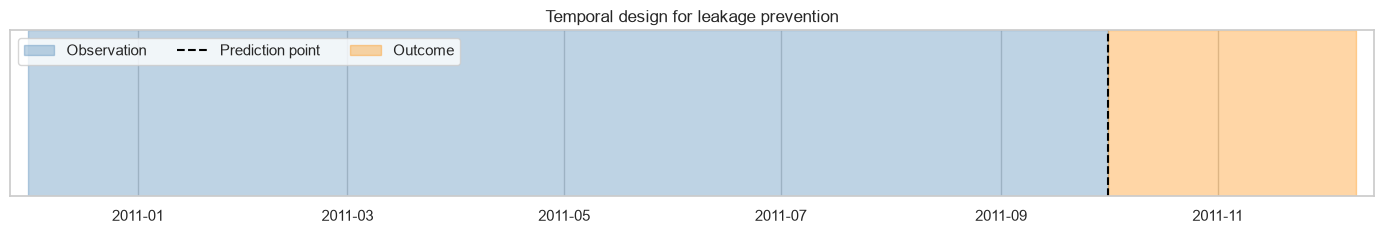

In [4]:
observation = df[(df['InvoiceDate'] >= OBSERVATION_START) & (df['InvoiceDate'] <= OBSERVATION_END)].copy()
outcome = df[(df['InvoiceDate'] >= OUTCOME_START) & (df['InvoiceDate'] <= OUTCOME_END)].copy()
print(f'Observation rows: {len(observation):,}')
print(f'Outcome rows: {len(outcome):,}')

timeline = pd.DataFrame({
    'Window': ['Observation', 'Prediction point', 'Outcome'],
    'Start': [OBSERVATION_START, PREDICTION_POINT, OUTCOME_START],
    'End': [OBSERVATION_END, PREDICTION_POINT, OUTCOME_END],
    'Purpose': ['Build features', 'Freeze information available to model', 'Define active or inactive target'],
})
timeline.to_csv(PROCESSED_PATH / 'temporal_windows.csv', index=False)
display(timeline)

fig, axis = plt.subplots(figsize=(14, 2.5))
axis.axvspan(OBSERVATION_START, OBSERVATION_END, alpha=0.35, color='steelblue', label='Observation')
axis.axvline(PREDICTION_POINT, color='black', linestyle='--', label='Prediction point')
axis.axvspan(OUTCOME_START, OUTCOME_END, alpha=0.35, color='darkorange', label='Outcome')
axis.set_xlim(OBSERVATION_START - pd.Timedelta(days=5), OUTCOME_END + pd.Timedelta(days=5))
axis.set_yticks([])
axis.set_title('Temporal design for leakage prevention')
axis.legend(loc='upper left', ncol=3)
plt.tight_layout()
plt.savefig(FIGURES_PATH / 'temporal_split_design.png', dpi=160, bbox_inches='tight')
plt.show()

In [5]:
outcome_customers = set(outcome['CustomerID'].unique())
observation_customers = sorted(observation['CustomerID'].unique())
target = pd.DataFrame({'CustomerID': observation_customers})
target['inactive_in_outcome_window'] = (~target['CustomerID'].isin(outcome_customers)).astype(int)
target_summary = target['inactive_in_outcome_window'].value_counts().rename_axis('target').reset_index(name='customers')
target_summary['percentage'] = target_summary['customers'] / len(target)
target_summary.to_csv(PROCESSED_PATH / 'target_balance.csv', index=False)
display(target_summary)
print('The positive class is inactive/churned: 1. Target is assigned only after all features are built.')

,target,customers,percentage
0,0,1887,0.515856
1,1,1771,0.484144


The positive class is inactive/churned: 1. Target is assigned only after all features are built.


## 3. Customer-level feature engineering

The feature table has one row per customer and uses observation-window records only. Revenue is net transaction value, while returns are separately measured.

In [6]:
def slope_of_monthly_spend(group):
    monthly = group.groupby('Month')['RevenueModel'].sum()
    if len(monthly) < 2:
        return 0.0
    x = np.arange(len(monthly), dtype=float)
    return float(np.polyfit(x, monthly.to_numpy(dtype=float), 1)[0])

observation = observation.sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo']).copy()
observation_net_product = (observation.groupby(['CustomerID', 'StockCode'], as_index=False)
    .agg(net_quantity=('Quantity', 'sum'), mean_unit_price=('UnitPrice', 'mean')))
observation_net_product['net_revenue'] = observation_net_product['net_quantity'] * observation_net_product['mean_unit_price']
observation_net_product.to_csv(PROCESSED_PATH / 'net_customer_product_values.csv', index=False)
observation_net_customer = observation_net_product.groupby('CustomerID')['net_revenue'].sum().rename('monetary_total_net').reset_index()

grouped = observation.groupby('CustomerID', sort=True)
features = grouped.agg(
    first_purchase=('InvoiceDate', 'min'),
    last_purchase=('InvoiceDate', 'max'),
    frequency_count=('InvoiceNo', 'nunique'),
    monetary_total=('RevenueModel', 'sum'),
    monetary_avg=('RevenueModel', 'mean'),
    monetary_std=('RevenueModel', 'std'),
    product_diversity=('StockCode', 'nunique'),
    avg_quantity_per_invoice=('QuantityModel', 'mean'),
    return_value=('ReturnValue', 'sum'),
    return_transaction_count=('Quantity', lambda values: int((values < 0).sum())),
    transaction_count=('InvoiceNo', 'size'),
    weekend_ratio=('IsWeekend', 'mean'),
    country=('CountryModel', lambda values: values.mode().iat[0] if not values.mode().empty else 'Other'),
).reset_index()
features = features.drop(columns=['monetary_total']).merge(observation_net_customer, on='CustomerID', how='left')
features = features.rename(columns={'monetary_total_net': 'monetary_total'})

features['monetary_std'] = features['monetary_std'].fillna(0)
features['recency_days'] = (PREDICTION_POINT - features['last_purchase']).dt.total_seconds() / 86400
features['tenure_days'] = (features['last_purchase'] - features['first_purchase']).dt.total_seconds() / 86400
features['days_since_first_purchase'] = (PREDICTION_POINT - features['first_purchase']).dt.total_seconds() / 86400
features['history_days'] = (PREDICTION_POINT - features['first_purchase']).dt.total_seconds() / 86400
features['return_rate'] = features['return_transaction_count'] / features['transaction_count'].replace(0, np.nan)
features['return_rate'] = features['return_rate'].fillna(0)
features['product_diversity_per_invoice'] = features['product_diversity'] / features['frequency_count'].replace(0, np.nan)
features['product_diversity_per_invoice'] = features['product_diversity_per_invoice'].fillna(0)
features['purchase_velocity'] = features['frequency_count'] / (features['history_days'].clip(lower=30) / 30)
features['purchases_per_month'] = features['frequency_count'] / (features['history_days'].clip(lower=30) / 30)
features['spend_per_month'] = features['monetary_total'] / (features['history_days'].clip(lower=30) / 30)
features['recency_ratio'] = features['recency_days'] / features['history_days'].clip(lower=1)

intervals = observation.groupby('CustomerID')['InvoiceDate'].diff().dt.total_seconds().div(86400)
interval_stats = intervals.groupby(observation['CustomerID']).agg(purchase_interval_avg='mean', purchase_interval_std='std').reset_index()
features = features.merge(interval_stats, on='CustomerID', how='left')
features['purchase_interval_avg'] = features['purchase_interval_avg'].fillna(0)
features['purchase_interval_std'] = features['purchase_interval_std'].fillna(0)
features['purchase_interval_cv'] = (features['purchase_interval_std'] / features['purchase_interval_avg'].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan).fillna(0)

monthly_std = observation.groupby(['CustomerID', 'Month'])['RevenueModel'].sum().groupby('CustomerID').std().rename('monthly_spend_std').reset_index()
monthly_trend = observation.groupby('CustomerID').apply(slope_of_monthly_spend, include_groups=False).rename('monthly_spend_trend').reset_index()
active_months = observation.groupby('CustomerID')['Month'].nunique().rename('active_months').reset_index()
recent_60 = observation[observation['InvoiceDate'] >= PREDICTION_POINT - pd.Timedelta(days=60)].groupby('CustomerID').agg(
    recent_60d_frequency=('InvoiceNo', 'nunique'), recent_60d_spend=('RevenueModel', 'sum')
).reset_index()
recent_30 = observation[observation['InvoiceDate'] >= PREDICTION_POINT - pd.Timedelta(days=30)].groupby('CustomerID').agg(
    recent_30d_frequency=('InvoiceNo', 'nunique'), recent_30d_spend=('RevenueModel', 'sum')
).reset_index()
features = features.merge(monthly_std, on='CustomerID', how='left').merge(monthly_trend, on='CustomerID', how='left')
features = features.merge(active_months, on='CustomerID', how='left').merge(recent_60, on='CustomerID', how='left').merge(recent_30, on='CustomerID', how='left')
features['monthly_spend_std'] = features['monthly_spend_std'].fillna(0)
features['monthly_spend_trend'] = features['monthly_spend_trend'].fillna(0)
for column in ['active_months', 'recent_60d_frequency', 'recent_60d_spend', 'recent_30d_frequency', 'recent_30d_spend']:
    features[column] = features[column].fillna(0)
features['recent_spend_ratio'] = features['recent_60d_spend'] / features['monetary_total'].abs().replace(0, np.nan)
features['recent_spend_ratio'] = features['recent_spend_ratio'].replace([np.inf, -np.inf], np.nan).fillna(0)
features = features.merge(target, on='CustomerID', how='left')

# Customers with fewer than three invoices do not provide a stable behavioral history.
# They are excluded from supervised modeling, while the raw and cleaned transaction exports remain complete.
history_before_filter = features['CustomerID'].nunique()
features = features[features['frequency_count'] >= 3].copy()
history_filter_summary = pd.DataFrame({
    'criterion': ['minimum unique invoices in observation window'],
    'threshold': [3],
    'customers_before': [history_before_filter],
    'customers_after': [features['CustomerID'].nunique()],
    'customers_removed': [history_before_filter - features['CustomerID'].nunique()],
})
history_filter_summary.to_csv(PROCESSED_PATH / 'customer_history_filter.csv', index=False)
features['CustomerID'] = features['CustomerID'].astype(str)
print(f'Customer feature rows after minimum-history filter: {len(features):,}')
display(history_filter_summary)
display(features.head())

Customer feature rows after minimum-history filter: 1,696


,criterion,threshold,customers_before,customers_after,customers_removed
0,minimum unique invoices in observation window,3,3658,1696,1962


,CustomerID,first_purchase,last_purchase,frequency_count,monetary_avg,monetary_std,product_diversity,avg_quantity_per_invoice,return_value,return_transaction_count,...,purchase_interval_cv,monthly_spend_std,monthly_spend_trend,active_months,recent_60d_frequency,recent_60d_spend,recent_30d_frequency,recent_30d_spend,recent_spend_ratio,inactive_in_outcome_window
1,12347,2010-12-07 14:57:00,2011-08-02 08:48:00,5,21.500484,17.085202,82,11.854839,0.00,0,...,5.529367,123.579764,-34.663,5,1.0,584.91,0.0,0.00,0.209581,0
2,12348,2010-12-16 19:09:00,2011-09-25 13:13:00,4,49.370323,37.605036,22,70.870968,0.00,0,...,3.620687,241.072573,-116.424,4,1.0,285.00,1.0,285.00,0.156404,1
4,12352,2011-02-16 12:33:00,2011-09-28 14:58:00,10,13.858500,12.493700,47,4.287500,960.63,10,...,7.248910,164.098479,130.500,3,2.0,557.50,2.0,557.50,0.451900,0
10,12359,2011-01-12 12:43:00,2011-06-03 12:26:00,4,18.905379,12.874270,135,6.627586,35.80,2,...,7.273305,648.094201,94.160,4,0.0,0.00,0.0,0.00,0.000000,0
13,12362,2011-02-17 10:30:00,2011-09-28 12:04:00,7,16.965267,8.825298,121,8.300000,22.80,5,...,5.883672,190.879257,65.209,5,3.0,1273.54,1.0,822.19,0.498540,0


## 4. Leakage checks and feature documentation

In [7]:
feature_columns = [
    'recency_days', 'frequency_count', 'monetary_total', 'monetary_avg', 'monetary_std',
    'tenure_days', 'history_days', 'purchase_interval_avg', 'purchase_interval_std', 'purchase_interval_cv',
    'product_diversity', 'product_diversity_per_invoice', 'avg_quantity_per_invoice',
    'return_rate', 'return_value', 'country', 'weekend_ratio', 'monthly_spend_std',
    'monthly_spend_trend', 'days_since_first_purchase', 'purchase_velocity',
    'purchases_per_month', 'spend_per_month', 'recency_ratio', 'active_months',
]
leakage_checks = pd.DataFrame({
    'Feature': feature_columns,
    'Uses only observation window': ['Yes'] * len(feature_columns),
    'Verification method': ['All source rows filtered to InvoiceDate <= OBSERVATION_END before aggregation'] * len(feature_columns),
})
assert observation['InvoiceDate'].max() <= OBSERVATION_END
assert features['inactive_in_outcome_window'].notna().all()
assert features['CustomerID'].is_unique
leakage_checks.to_csv(DOCS_PATH / 'feature_leakage_checks.csv', index=False)
feature_log = '# Feature Engineering Log\n\n'
feature_log += 'All features are calculated from transactions dated from 2010-12-01 through 2011-09-30. Outcome-window activity is used only for the binary target.\n\n'
feature_log += 'Customers with fewer than three unique invoices are excluded from supervised modeling because their behavioral history is insufficient.\n\n'
feature_log += 'Absolute recent 30-day and 60-day features are retained for audit exploration but excluded from the modeling feature list because their meaning changes with customer age. Tenure-normalized features are used instead.\n\n'
feature_log += leakage_checks.to_string(index=False)
feature_log += '\n\n### Target alternatives considered\n\n'
feature_log += '- No purchase for a fixed number of days: rejected because the outcome window provides a consistent business horizon.\n'
feature_log += '- Revenue below a threshold: rejected because it confounds retention with purchase value.\n'
feature_log += '- Frequency drop: rejected because it requires a customer-specific historical baseline and is less directly actionable.\n'
(DOCS_PATH / 'feature_engineering_log.md').write_text(feature_log, encoding='utf-8')
print('Leakage assertions passed.')

Leakage assertions passed.


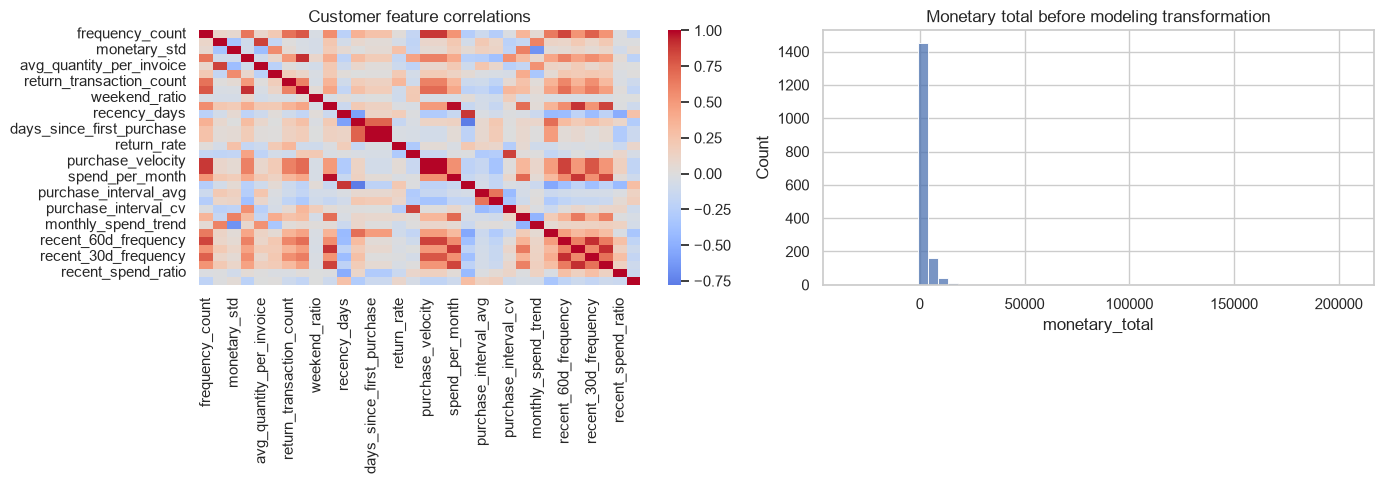

Wrote D:\Year3\Retail_Separate_Notebooks\data\processed\customer_features.csv
Wrote D:\Year3\Retail_Separate_Notebooks\data\processed\cleaned_transactions.csv


In [8]:
numeric_features = features.select_dtypes(include=np.number).columns.tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(features[numeric_features].corr(), cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Customer feature correlations')
sns.histplot(data=features, x='monetary_total', bins=50, ax=axes[1])
axes[1].set_title('Monetary total before modeling transformation')
plt.tight_layout()
plt.savefig(FIGURES_PATH / 'feature_distributions_and_correlations.png', dpi=160, bbox_inches='tight')
plt.show()

features.to_csv(PROCESSED_PATH / 'customer_features.csv', index=False)
observation.to_csv(PROCESSED_PATH / 'cleaned_transactions.csv', index=False)
print('Wrote', PROCESSED_PATH / 'customer_features.csv')
print('Wrote', PROCESSED_PATH / 'cleaned_transactions.csv')

## Phase 2 outputs

This notebook writes `cleaned_transactions.csv`, `customer_features.csv`, `target_balance.csv`, `temporal_windows.csv`, `preprocessing_log.md`, `feature_engineering_log.md`, `feature_leakage_checks.csv`, and the temporal and feature diagnostic plots. Phase 3 will train and compare models from `customer_features.csv`.

In [9]:
# Rolling customer snapshots for temporal training and evaluation.
# Each row is one customer at one prediction date; outcome data is never used as a feature.
from pandas.tseries.offsets import DateOffset

SNAPSHOT_DATES = pd.to_datetime([
    '2011-03-31', '2011-04-30', '2011-05-31',
    '2011-06-30', '2011-07-31', '2011-08-31',
])
SNAPSHOT_OBSERVATION_MONTHS = 6
SNAPSHOT_OUTCOME_MONTHS = 2
SNAPSHOT_MIN_PURCHASES = 2
SNAPSHOT_MIN_TENURE_DAYS = 60


def build_snapshot_features(observation_snapshot, prediction_date):
    """Build leakage-safe customer features for one prediction date."""
    if observation_snapshot.empty:
        return pd.DataFrame()
    observation_snapshot = observation_snapshot.sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo']).copy()
    grouped_snapshot = observation_snapshot.groupby('CustomerID', sort=True)
    snapshot_features = grouped_snapshot.agg(
        first_purchase=('InvoiceDate', 'min'),
        last_purchase=('InvoiceDate', 'max'),
        frequency_count=('InvoiceNo', 'nunique'),
        monetary_total=('RevenueModel', 'sum'),
        monetary_avg=('RevenueModel', 'mean'),
        monetary_std=('RevenueModel', 'std'),
        product_diversity=('StockCode', 'nunique'),
        product_diversity_per_invoice=('StockCode', lambda values: values.nunique()),
        avg_quantity_per_invoice=('QuantityModel', 'mean'),
        return_value=('ReturnValue', 'sum'),
        return_transaction_count=('Quantity', lambda values: int((values < 0).sum())),
        transaction_count=('InvoiceNo', 'size'),
        weekend_ratio=('IsWeekend', 'mean'),
        country=('CountryModel', lambda values: values.mode().iat[0] if not values.mode().empty else 'Other'),
    ).reset_index()
    snapshot_features['monetary_std'] = snapshot_features['monetary_std'].fillna(0)
    snapshot_features['recency_days'] = (prediction_date - snapshot_features['last_purchase']).dt.total_seconds() / 86400
    snapshot_features['tenure_days'] = (snapshot_features['last_purchase'] - snapshot_features['first_purchase']).dt.total_seconds() / 86400
    snapshot_features['history_days'] = (prediction_date - snapshot_features['first_purchase']).dt.total_seconds() / 86400
    snapshot_features['days_since_first_purchase'] = snapshot_features['history_days']
    snapshot_features['return_rate'] = snapshot_features['return_transaction_count'] / snapshot_features['transaction_count'].replace(0, np.nan)
    snapshot_features['return_rate'] = snapshot_features['return_rate'].fillna(0)
    snapshot_features['product_diversity_per_invoice'] = snapshot_features['product_diversity_per_invoice'] / snapshot_features['frequency_count'].replace(0, np.nan)
    snapshot_features['product_diversity_per_invoice'] = snapshot_features['product_diversity_per_invoice'].fillna(0)
    snapshot_features['purchase_velocity'] = snapshot_features['frequency_count'] / (snapshot_features['history_days'].clip(lower=30) / 30)
    snapshot_features['purchases_per_month'] = snapshot_features['purchase_velocity']
    snapshot_features['spend_per_month'] = snapshot_features['monetary_total'] / (snapshot_features['history_days'].clip(lower=30) / 30)
    snapshot_features['recency_ratio'] = snapshot_features['recency_days'] / snapshot_features['history_days'].clip(lower=1)

    invoice_dates = observation_snapshot.drop_duplicates(['CustomerID', 'InvoiceNo']).sort_values(['CustomerID','InvoiceDate'])
    intervals = invoice_dates.groupby('CustomerID')['InvoiceDate'].diff().dt.total_seconds().div(86400)
    interval_stats = intervals.groupby(invoice_dates['CustomerID']).agg(
        purchase_interval_avg='mean', purchase_interval_std='std').reset_index()
    snapshot_features = snapshot_features.merge(interval_stats, on='CustomerID', how='left')
    snapshot_features['purchase_interval_avg'] = snapshot_features['purchase_interval_avg'].fillna(0)
    snapshot_features['purchase_interval_std'] = snapshot_features['purchase_interval_std'].fillna(0)
    snapshot_features['purchase_interval_cv'] = (
        snapshot_features['purchase_interval_std'] / snapshot_features['purchase_interval_avg'].replace(0, np.nan)
    ).replace([np.inf, -np.inf], np.nan).fillna(0)
    monthly_spend = observation_snapshot.assign(SnapshotMonth=observation_snapshot['InvoiceDate'].dt.to_period('M'))
    monthly_stats = monthly_spend.groupby(['CustomerID', 'SnapshotMonth'])['RevenueModel'].sum()
    monthly_std = monthly_stats.groupby('CustomerID').std().rename('monthly_spend_std').reset_index()
    snapshot_features = snapshot_features.merge(monthly_std, on='CustomerID', how='left')
    snapshot_features['monthly_spend_std'] = snapshot_features['monthly_spend_std'].fillna(0)
    snapshot_features['monthly_spend_trend'] = 0.0
    snapshot_features['active_months'] = observation_snapshot.assign(
        SnapshotMonth=observation_snapshot['InvoiceDate'].dt.to_period('M')
    ).groupby('CustomerID')['SnapshotMonth'].nunique().reindex(snapshot_features['CustomerID']).to_numpy()
    snapshot_features['active_months'] = snapshot_features['active_months'].fillna(0)
    return snapshot_features


snapshot_frames = []
for prediction_date in SNAPSHOT_DATES:
    observation_start = prediction_date - DateOffset(months=SNAPSHOT_OBSERVATION_MONTHS)
    outcome_end = prediction_date + DateOffset(months=SNAPSHOT_OUTCOME_MONTHS)
    observation_snapshot = df[(df['InvoiceDate'] >= observation_start) & (df['InvoiceDate'] < prediction_date)].copy()
    # Learn transformations from this snapshot's past only, never the full future dataset.
    qcap = observation_snapshot.loc[observation_snapshot.Quantity > 0, 'Quantity'].quantile(.99)
    pcap = observation_snapshot.UnitPrice.quantile(.99)
    observation_snapshot['QuantityModel'] = observation_snapshot.Quantity.clip(upper=qcap)
    observation_snapshot['UnitPriceModel'] = observation_snapshot.UnitPrice.clip(upper=pcap)
    observation_snapshot['RevenueModel'] = observation_snapshot.QuantityModel * observation_snapshot.UnitPriceModel
    top = observation_snapshot.Country.value_counts().head(5).index
    observation_snapshot['CountryModel'] = observation_snapshot.Country.where(observation_snapshot.Country.isin(top), 'Other')
    outcome_snapshot = df[(df['InvoiceDate'] >= prediction_date) & (df['InvoiceDate'] < outcome_end)].copy()
    snapshot_features = build_snapshot_features(observation_snapshot, prediction_date)
    if snapshot_features.empty:
        continue
    active_customers = set(outcome_snapshot.loc[(outcome_snapshot.Quantity > 0) & ~outcome_snapshot.IsCancellation, 'CustomerID'].unique())
    snapshot_features['inactive_in_outcome_window'] = (~snapshot_features['CustomerID'].isin(active_customers)).astype(int)
    snapshot_features = snapshot_features[
        (snapshot_features['frequency_count'] >= SNAPSHOT_MIN_PURCHASES)
        & (snapshot_features['history_days'] >= SNAPSHOT_MIN_TENURE_DAYS)
    ].copy()
    snapshot_features['prediction_date'] = prediction_date
    snapshot_features['snapshot_id'] = f'snap_{prediction_date:%Y%m%d}'
    snapshot_frames.append(snapshot_features)

snapshot_data = pd.concat(snapshot_frames, ignore_index=True)
snapshot_data['CustomerID'] = snapshot_data['CustomerID'].astype(str)
snapshot_data.to_csv(PROCESSED_PATH / 'customer_snapshot_features.csv', index=False)
snapshot_summary = snapshot_data.groupby('snapshot_id').agg(
    prediction_date=('prediction_date', 'first'), records=('CustomerID', 'size'),
    customers=('CustomerID', 'nunique'), inactive_rate=('inactive_in_outcome_window', 'mean')
).reset_index()
snapshot_summary.to_csv(PROCESSED_PATH / 'snapshot_summary.csv', index=False)
print(f'Combined customer-snapshot records: {len(snapshot_data):,}')
print(f'Unique customers across snapshots: {snapshot_data["CustomerID"].nunique():,}')
print(f'Snapshots created: {snapshot_data["snapshot_id"].nunique()}')
display(snapshot_summary)

Combined customer-snapshot records: 8,004
Unique customers across snapshots: 1,994
Snapshots created: 6


,snapshot_id,prediction_date,records,customers,inactive_rate
0,snap_20110331,2011-03-31,854,854,0.359485
1,snap_20110430,2011-04-30,1122,1122,0.392157
2,snap_20110531,2011-05-31,1412,1412,0.443343
3,snap_20110630,2011-06-30,1460,1460,0.456849
4,snap_20110731,2011-07-31,1553,1553,0.426272
5,snap_20110831,2011-08-31,1603,1603,0.380536


## Recent positive-purchase features
The model keeps the original customer cohort and target for comparison. Additional signals use only positive, non-cancelled invoices before each cutoff: 30/60/90-day activity, order-level value and quantity, recent changes and overdue purchasing. Existing legacy aggregates remain identifiable; recent signals never use globally clipped columns.


In [10]:
import sys
sys.path.insert(0, str(PROJECT_ROOT/'src'))
from model_workflow import enrich_snapshots, RECENT_FEATURES
snapshot_data = enrich_snapshots(snapshot_data, df)
snapshot_data.to_csv(PROCESSED_PATH/'customer_snapshot_features.csv', index=False)
display(snapshot_data[['CustomerID','prediction_date']+RECENT_FEATURES].head())


,CustomerID,prediction_date,positive_recency_days,positive_invoice_count,positive_order_value,positive_quantity_per_invoice,days_overdue,orders_30d,orders_60d,orders_90d,spend_30d,spend_60d,spend_90d,order_trend,spend_trend
0,12346,2011-03-31,71.582639,1.0,77183.600,74215.000000,NaN,0.0,0.0,1.0,0.00,0.00,77183.60,1.0,1.000000
1,12347,2011-03-31,63.395833,2.0,593.590,317.000000,1.268392,0.0,0.0,1.0,0.00,0.00,475.39,1.0,1.000000
2,12348,2011-03-31,64.554167,2.0,560.120,927.500000,1.628186,0.0,0.0,1.0,0.00,0.00,227.44,1.0,1.000000
3,12359,2011-03-31,51.381250,2.0,1193.205,304.500000,1.969469,0.0,1.0,2.0,0.00,1838.91,2386.41,0.5,0.000544
4,12370,2011-03-31,20.466667,3.0,934.220,657.333333,0.476007,1.0,1.0,1.0,938.39,938.39,938.39,2.0,939.390000
